In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
df=pd.read_csv('/content/cars_data.csv')

In [5]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015.0,110373.0,2.5,Electric,Manual,2,3000.0
1,Mercedes,2010.0,186144.0,1.3,Electric,Manual,5,4844.0
2,Nissan,2018.0,29574.0,2.6,Petrol,Manual,1,6628.0
3,Kia,2010.0,139502.0,2.4,Diesel,Automatic,NaN,3000.0
4,BMW,2014.0,148748.0,3.5,Diesel,Manual,1,6451.0


In [6]:
df.shape

(1000, 8)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Brand            979 non-null    object 
 1   Year             974 non-null    float64
 2   Mileage          979 non-null    float64
 3   Engine_Size      964 non-null    float64
 4   Fuel_Type        982 non-null    object 
 5   Transmission     962 non-null    object 
 6   Previous_Owners  950 non-null    object 
 7   Price            987 non-null    float64
dtypes: float64(4), object(4)
memory usage: 62.6+ KB


In [8]:
df.describe()

,Year,Mileage,Engine_Size,Price
count,974.000000,979.000000,964.000000,987.000000
mean,2016.320329,104185.955056,2.490560,8473.716312
std,4.050561,56333.931315,0.866082,6301.920977
min,2010.000000,5207.000000,1.000000,3000.000000
25%,2013.000000,54002.500000,1.800000,4068.000000
50%,2016.000000,104853.000000,2.500000,6426.000000
75%,2020.000000,155030.000000,3.200000,10917.000000
max,2023.000000,199812.000000,4.000000,43994.000000


In [9]:
df.isnull().sum()

,0
Brand,21
Year,26
Mileage,21
Engine_Size,36
Fuel_Type,18
Transmission,38
Previous_Owners,50
Price,13


In [10]:
df.dropna(axis=0,inplace=True)

In [11]:
df.shape

(874, 8)

In [12]:
df.duplicated().sum()

np.int64(0)

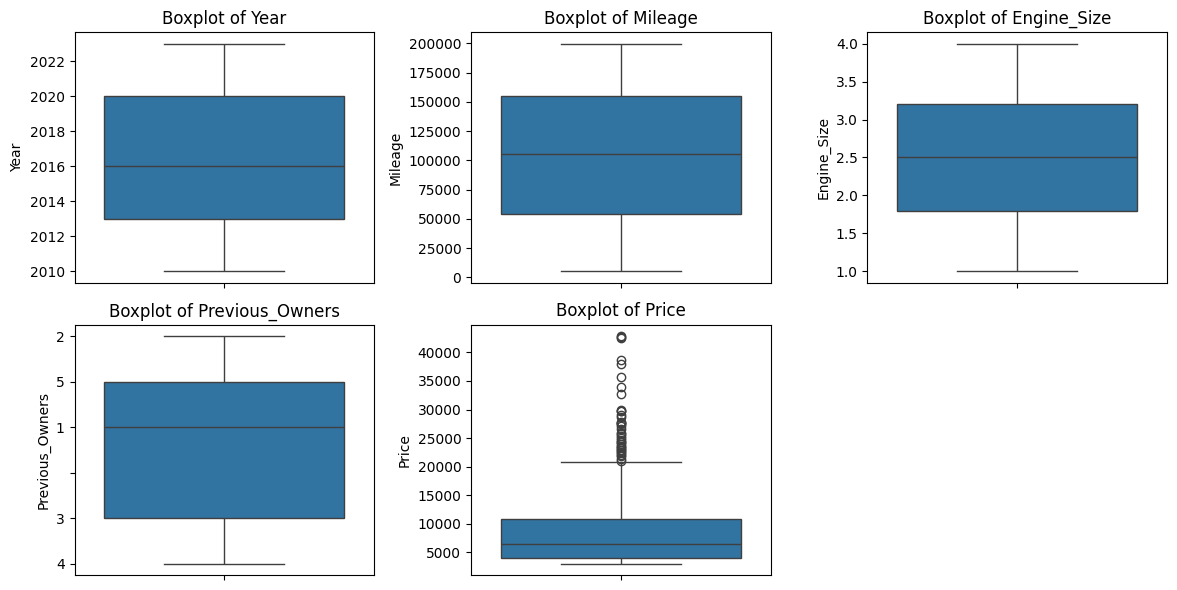

In [13]:
numeric_cols = [
    'Year',
    'Mileage',
    'Engine_Size',
    'Previous_Owners',
    'Price'
]


plt.figure(figsize=(12, 6))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

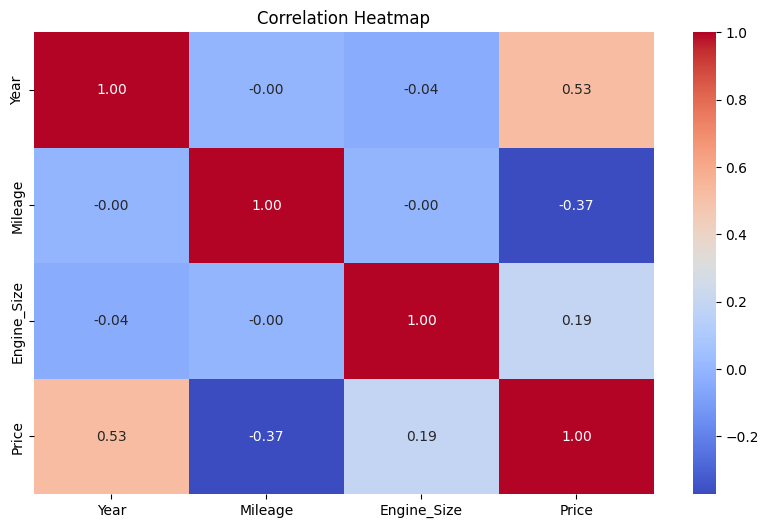

In [14]:


numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

plt.figure(figsize=(10, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()


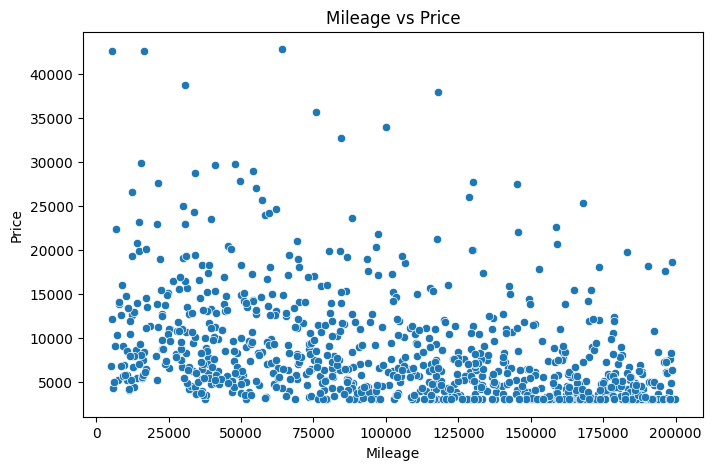

In [15]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Mileage",
    y="Price"
)

plt.title("Mileage vs Price")
plt.xlabel("Mileage")
plt.ylabel("Price")

plt.show()


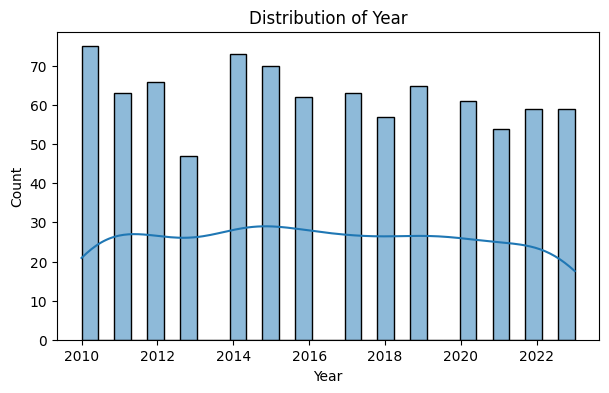

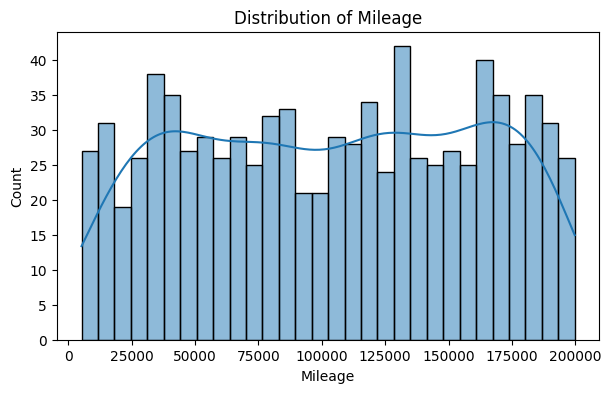

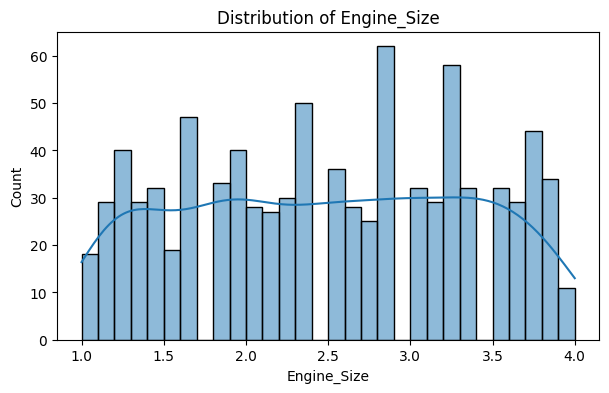

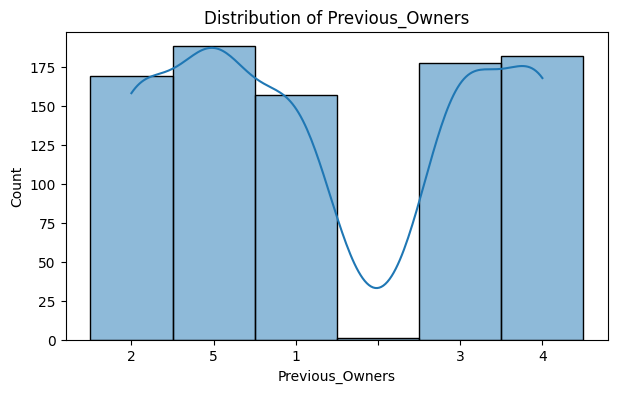

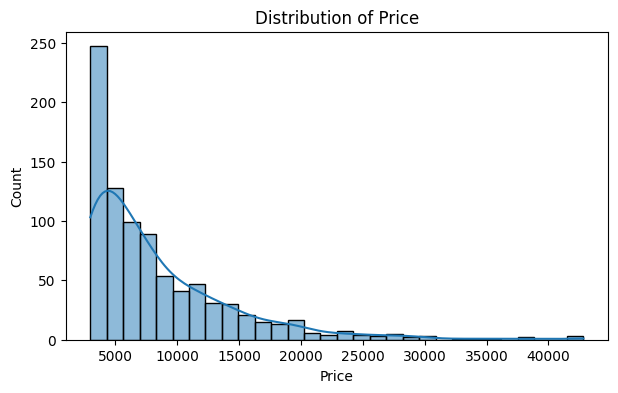

In [16]:


for col in numeric_cols:

    plt.figure(figsize=(7, 4))

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=30
    )

    plt.title(f"Distribution of {col}")
    plt.show()


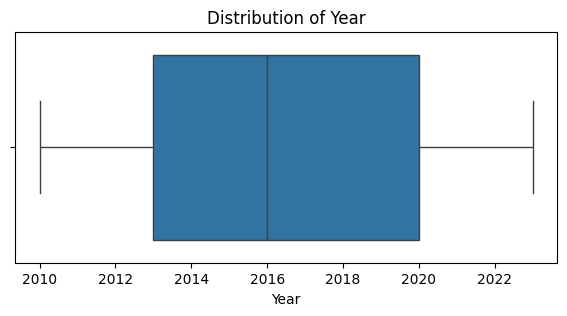

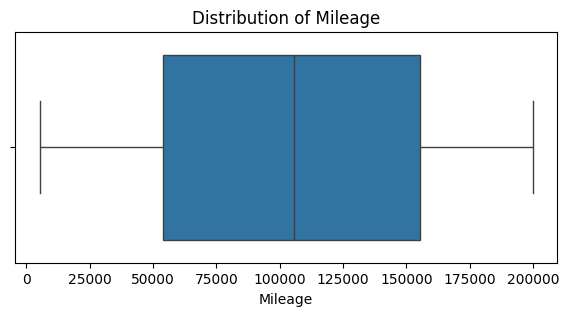

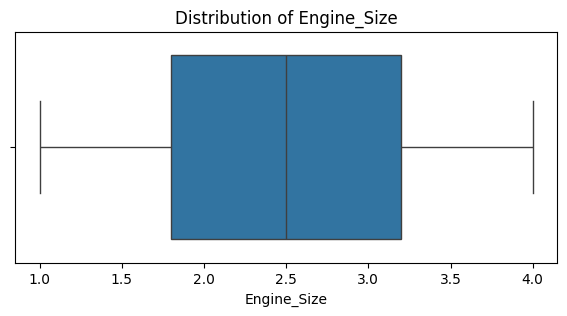

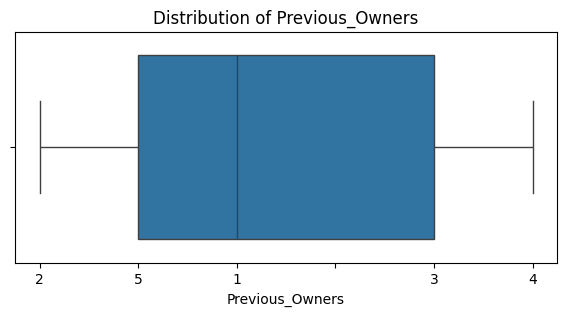

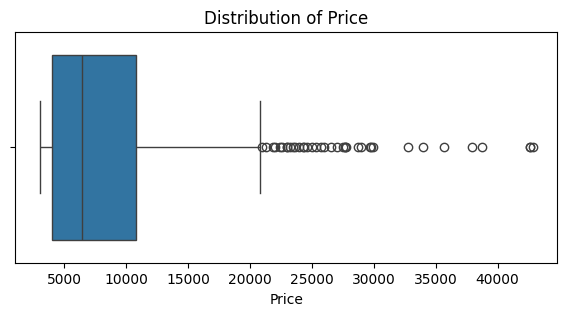

In [17]:

for col in numeric_cols:

    plt.figure(figsize=(7, 3))

    sns.boxplot(data=df, x=col)

    plt.title(f"Distribution of {col}")
    plt.show()


In [18]:

Q1 = df['Price'].quantile(0.25)
Q3 = df['Price'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df['Price'] < lower) |
    (df['Price'] > upper)
]


print("Number of Outliers:", len(outliers))

df = df[
    (df['Price'] >= lower) &
    (df['Price'] <= upper)
].copy()

Number of Outliers: 38


In [19]:
from sklearn.preprocessing import LabelEncoder
lb=LabelEncoder()
df['Brand']=lb.fit_transform(df['Brand'])
df['Transmission']=lb.fit_transform(df['Transmission'])
df['Fuel_Type']=lb.fit_transform(df['Fuel_Type'])


In [20]:
from sklearn.model_selection import train_test_split
X=df.drop('Price',axis=1)
y=df['Price']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42
)


In [21]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

X_train['Previous_Owners'] = pd.to_numeric(X_train['Previous_Owners'], errors='coerce')
X_test['Previous_Owners'] = pd.to_numeric(X_test['Previous_Owners'], errors='coerce')

median_owners = X_train['Previous_Owners'].median()
X_train['Previous_Owners'] = X_train['Previous_Owners'].fillna(median_owners)
X_test['Previous_Owners'] = X_test['Previous_Owners'].fillna(median_owners)

sc = StandardScaler()
x_train = sc.fit_transform(X_train)
x_test = sc.transform(X_test)

In [22]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(x_train,y_train)
y_pred=model.predict(x_test)


In [23]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y_test,y_pred)
print('MAE:',mae)
print('MSE:',mse)
print('RMSE:',rmse)
print('R2:',r2)

MAE: 2228.3737324292
MSE: 8337426.64628237
RMSE: 2887.460241506776
R2: 0.5252378759510079


In [24]:
pip install xgboost lightgbm catboost

In [25]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [26]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

In [27]:
from tqdm import tqdm

In [28]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from tqdm import tqdm
import pandas as pd
import numpy as np

# Redefine models for Regression
reg_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(random_state=1),
    "Lasso Regression": Lasso(random_state=1),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=100, random_state=1),
    "Gradient Boosting Regressor": GradientBoostingRegressor(random_state=1),
    "XGBoost Regressor": XGBRegressor(random_state=1),
    "LightGBM Regressor": LGBMRegressor(random_state=1, verbose=-1),
    "CatBoost Regressor": CatBoostRegressor(verbose=0, random_state=1)
}

results = {}

for name, model in tqdm(reg_models.items()):
    # Train the model
    model.fit(x_train, y_train)

    # Make predictions
    train_pred = model.predict(x_train)
    test_pred  = model.predict(x_test)

    # Calculate Regression Metrics
    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)

    train_mae = mean_absolute_error(y_train, train_pred)
    test_mae = mean_absolute_error(y_test, test_pred)

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))

    results[name] = {
        "Train R2 Score": train_r2,
        "Test R2 Score": test_r2,
        "Train MAE": train_mae,
        "Test MAE": test_mae,
        "Train RMSE": train_rmse,
        "Test RMSE": test_rmse
    }

# Display Results
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test R2 Score", ascending=False)
print(results_df)

 75%|███████▌  | 6/8 [00:01<00:00,  3.97it/s]/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
100%|██████████| 8/8 [00:04<00:00,  1.79it/s]

                             Train R2 Score  Test R2 Score    Train MAE  \
CatBoost Regressor                 0.993644       0.904991   269.035988   
LightGBM Regressor                 0.979418       0.869581   449.118074   
XGBoost Regressor                  0.999846       0.859257    36.935074   
Gradient Boosting Regressor        0.936284       0.857640   826.604959   
Random Forest Regressor            0.967513       0.741510   553.072207   
Ridge Regression                   0.484955       0.525348  2432.483369   
Lasso Regression                   0.484955       0.525291  2432.628791   
Linear Regression                  0.484956       0.525238  2432.734781   

                                Test MAE   Train RMSE    Test RMSE  
CatBoost Regressor            869.884181   351.402984  1291.695837  
LightGBM Regressor           1030.179200   632.335222  1513.382228  
XGBoost Regressor            1101.234825    54.669911  1572.142562  
Gradient Boosting Regressor  1121.654115  1112.5

Voting Regressor Train R2 Score: 0.9499
Voting Regressor Test R2 Score: 0.8370
Voting Regressor Test MAE: 1152.76
Voting Regressor Test RMSE: 1692.04


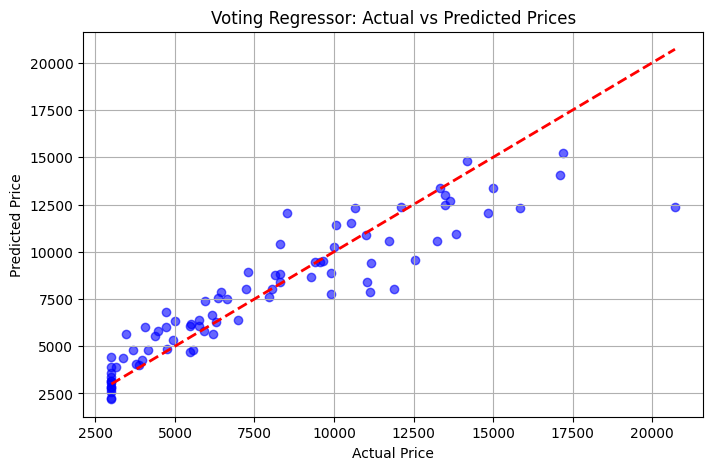

In [29]:
from sklearn.ensemble import VotingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

# Define the Voting Regressor using your regression models
voting_reg = VotingRegressor(
    estimators=[
        ("lr", reg_models["Linear Regression"]),
        ("rf", reg_models["Random Forest Regressor"]),
        ("xgb", reg_models["XGBoost Regressor"]),
        ("cat", reg_models["CatBoost Regressor"])
    ]
)

# Train
voting_reg.fit(x_train, y_train)
voting_train_pred = voting_reg.predict(x_train)
voting_test_pred = voting_reg.predict(x_test)

# Evaluate using regression metrics
train_r2 = r2_score(y_train, voting_train_pred)
test_r2 = r2_score(y_test, voting_test_pred)
test_mae = mean_absolute_error(y_test, voting_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, voting_test_pred))

print(f"Voting Regressor Train R2 Score: {train_r2:.4f}")
print(f"Voting Regressor Test R2 Score: {test_r2:.4f}")
print(f"Voting Regressor Test MAE: {test_mae:.2f}")
print(f"Voting Regressor Test RMSE: {test_rmse:.2f}")

# Plot Actual vs Predicted prices
plt.figure(figsize=(8, 5))
plt.scatter(y_test, voting_test_pred, alpha=0.6, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Voting Regressor: Actual vs Predicted Prices')
plt.grid(True)
plt.show()

# Store results
results["Voting Regressor"] = {
    "Train R2 Score": train_r2,
    "Test R2 Score": test_r2,
    "Train MAE": mean_absolute_error(y_train, voting_train_pred),
    "Test MAE": test_mae,
    "Train RMSE": np.sqrt(mean_squared_error(y_train, voting_train_pred)),
    "Test RMSE": test_rmse
}

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but Ridge was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but Ridge was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

Stacking Regressor Train R2 Score: -0.5151
Stacking Regressor Test R2 Score: -0.6641
Stacking Regressor Test MAE: 4429.10
Stacking Regressor Test RMSE: 5405.86


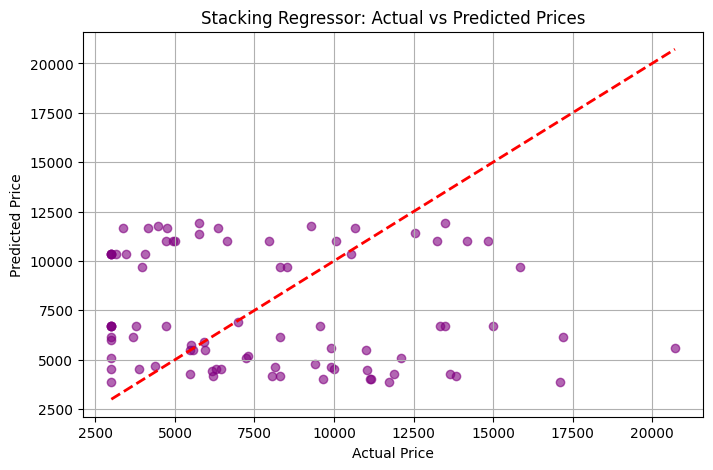

In [30]:
from sklearn.ensemble import StackingRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge

# Define the Stacking Regressor for continuous target (Price)
stack_reg = StackingRegressor(
    estimators=[
        ("ridge", Ridge(random_state=1)),
        ("rf", RandomForestRegressor(n_estimators=100, random_state=1)),
        ("lgbm", LGBMRegressor(random_state=1, verbose=-1))
    ],
    final_estimator=CatBoostRegressor(verbose=0, random_state=1),
    n_jobs=-1
)

# Train
stack_reg.fit(X_train, y_train)

# Predictions
stack_train_pred = stack_reg.predict(x_train)
stack_test_pred  = stack_reg.predict(x_test)

# Metrics
train_r2 = r2_score(y_train, stack_train_pred)
test_r2 = r2_score(y_test, stack_test_pred)
test_mae = mean_absolute_error(y_test, stack_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, stack_test_pred))

print(f"Stacking Regressor Train R2 Score: {train_r2:.4f}")
print(f"Stacking Regressor Test R2 Score: {test_r2:.4f}")
print(f"Stacking Regressor Test MAE: {test_mae:.2f}")
print(f"Stacking Regressor Test RMSE: {test_rmse:.2f}")

# Plot Actual vs Predicted prices
plt.figure(figsize=(8, 5))
plt.scatter(y_test, stack_test_pred, alpha=0.6, color='purple')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Stacking Regressor: Actual vs Predicted Prices')
plt.grid(True)
plt.show()

# Store results
results["Stacking Regressor"] = {
    "Train R2 Score": train_r2,
    "Test R2 Score": test_r2,
    "Train MAE": mean_absolute_error(y_train, stack_train_pred),
    "Test MAE": test_mae,
    "Train RMSE": np.sqrt(mean_squared_error(y_train, stack_train_pred)),
    "Test RMSE": test_rmse
}

In [31]:
# Compare all Regression models
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test R2 Score", ascending=False)
results_df

,Train R2 Score,Test R2 Score,Train MAE,Test MAE,Train RMSE,Test RMSE
CatBoost Regressor,0.993644,0.904991,269.035988,869.884181,351.402984,1291.695837
LightGBM Regressor,0.979418,0.869581,449.118074,1030.179200,632.335222,1513.382228
XGBoost Regressor,0.999846,0.859257,36.935074,1101.234825,54.669911,1572.142562
Gradient Boosting Regressor,0.936284,0.857640,826.604959,1121.654115,1112.565232,1581.145665
Voting Regressor,0.949935,0.836971,731.825488,1152.759088,986.212956,1692.037355
Random Forest Regressor,0.967513,0.741510,553.072207,1488.206310,794.432386,2130.591656
Ridge Regression,0.484955,0.525348,2432.483369,2228.346619,3163.187169,2887.124267
Lasso Regression,0.484955,0.525291,2432.628791,2228.296125,3163.185095,2887.298533
Linear Regression,0.484956,0.525238,2432.734781,2228.373732,3163.183937,2887.460242
Stacking Regressor,-0.515072,-0.664077,4242.777242,4429.095990,5425.237942,5405.858842


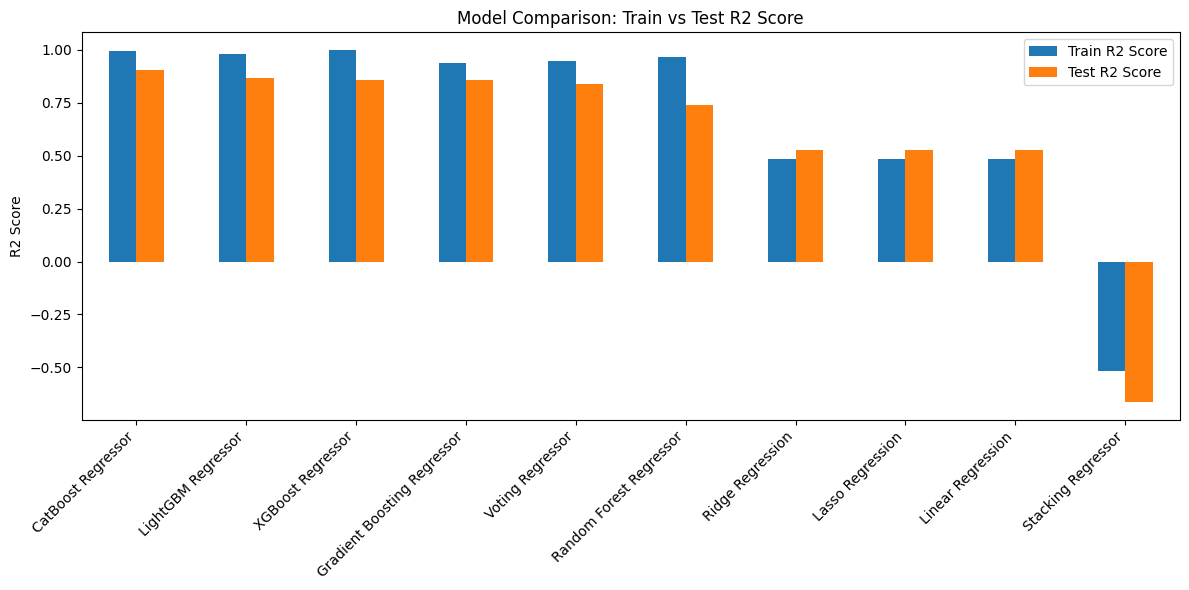

In [32]:
# Plot comparison of Train vs Test R2 Score
results_df[["Train R2 Score", "Test R2 Score"]].plot.bar(figsize=(12, 6))
plt.title("Model Comparison: Train vs Test R2 Score")
plt.ylabel("R2 Score")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

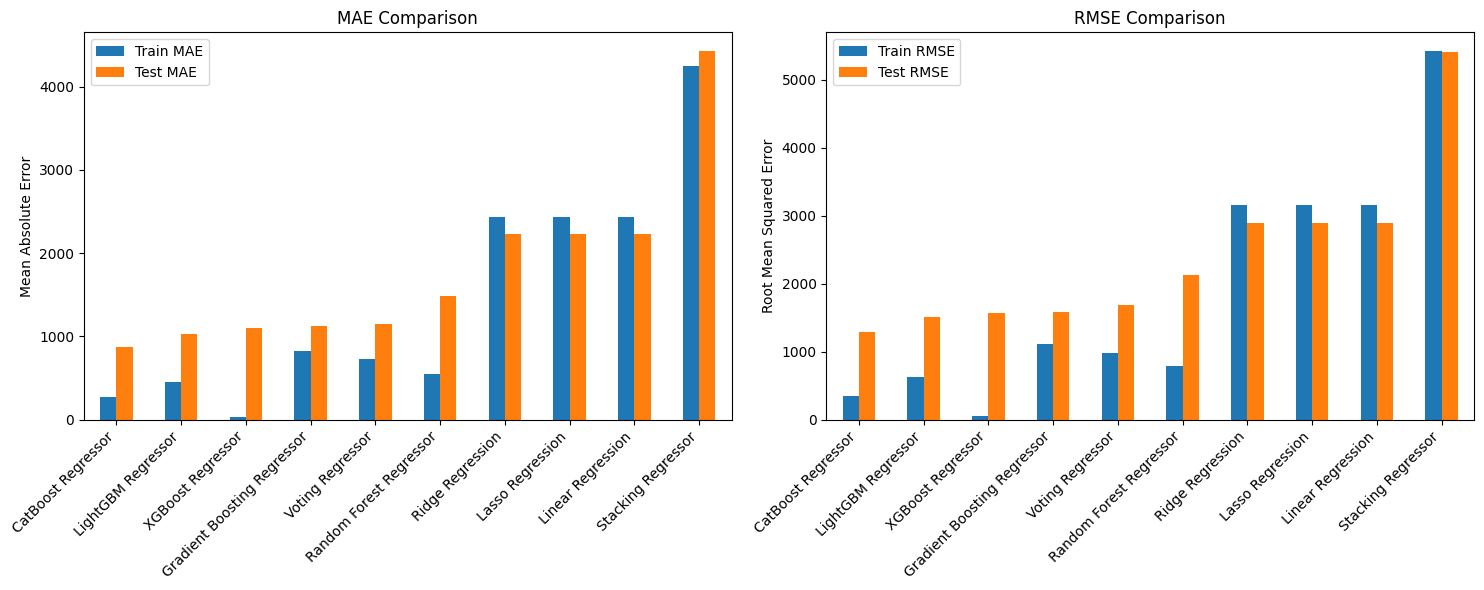

In [33]:
# Compare MAE and RMSE across models
plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
results_df[["Train MAE", "Test MAE"]].plot.bar(ax=plt.gca())
plt.title("MAE Comparison")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=45, ha='right')

plt.subplot(1, 2, 2)
results_df[["Train RMSE", "Test RMSE"]].plot.bar(ax=plt.gca())
plt.title("RMSE Comparison")
plt.ylabel("Root Mean Squared Error")
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()